# 06 — XGBoost: escada de evolução E0 → E3
Gradient Boosting (XGBoost) nas 3 partições, como modelo de comparação com o MLP. A lógica está em `src/xgb.py`; este notebook só **chama** o módulo, registra em `reports/tables/resultados_xgboost.csv` e mostra a evolução.

## Regras (as mesmas do MLP)
- **Escolhas (hiperparâmetros, variante, etapa) usam somente o KS de validação** (desempate: AUROC de validação). O **teste só é registrado**, nunca usado para escolher.
- Busca de hiperparâmetros **apenas no Fold 1**; a configuração escolhida é retreinada nos Folds 1, 2 e 3 com 3 sementes. Reportamos **média ± desvio** entre folds.
- Parada antecipada pela **log-loss de validação** (deviance, como no slide), paciência 20, até 2.000 árvores. O nº de árvores sai da parada, não da busca.
- Mesmos folds e mesmo oversampling do MLP (treino e validação 50/50; teste com a proporção real).

## Escada de evolução
| Etapa | O que muda | Variante |
|---|---|---|
| **E0_baseline** | Hiperparâmetros padrão do XGBoost, **todas as variáveis**, categóricas nativas | `arvore` |
| **E1_busca_arvore** | Busca Optuna (100 tentativas) | `arvore` |
| **E2_busca_onehot** | Busca Optuna (100 tentativas) com one-hot, para comparar a codificação | `neural` |
| **E3_final_3folds** | Melhor entre E1/E2 (por KS de validação), retreinada em 3 folds × 3 sementes | a escolhida |

## Tempo
Cada busca leva poucos minutos em CPU. O estudo Optuna fica em `models/optuna/` e **retoma** se for interrompido.

In [1]:
# No Colab: instalar o XGBoost se faltar (o Colab costuma já ter)
import importlib.util, subprocess, sys
if importlib.util.find_spec("xgboost") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xgboost"], check=True)

In [2]:
# Localiza a raiz do repositório (VS Code e Colab) e a coloca no sys.path
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("Raiz do projeto:", ROOT)

Raiz do projeto: /home/claude/churn/Projeto_Churn_Telecom-main


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import xgboost

from src import config as cfg
from src import xgb
from src.metrics import (load_results, summarize_folds, evolution_table, plot_evolution,
                         plot_ks, plot_roc, plot_confusion, save_figure, save_results)

cfg.ensure_dirs()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# ---- Parâmetros do experimento (alterar apenas aqui) ----
FOLD_BUSCA = 1           # a busca é SOMENTE no Fold 1
N_TRIALS = 100           # tentativas Optuna por variante (total; retoma se já existirem)
SEEDS = (42, 43, 44)     # sementes (subsample/colsample tornam o treino aleatório)
TOP_K = 5                # tentativas reavaliadas com 3 sementes
TIMEOUT_BUSCA = None     # segundos por variante (None = sem limite)
DEVICE = "cpu"           # "cuda" se houver GPU; com essa base a CPU já é rápida

print("XGBoost:", xgboost.__version__, "| dispositivo:", DEVICE, "| semente base:", cfg.SEED)

XGBoost: 3.4.1 | dispositivo: cpu | semente base: 42


## E0 — Baseline: hiperparâmetros padrão, todas as variáveis
Primeiro modelo sem ajuste nenhum (taxa de aprendizagem 0,3, profundidade 6). As 16 categóricas entram como `category` do pandas; as categorias são aprendidas só no treino do fold.

In [4]:
X_tr, y_tr = xgb.load_xy(FOLD_BUSCA, "arvore")["treino"]
faltando = [c for c in cfg.FEATURE_COLS if c not in X_tr.columns]
assert not faltando, f"variáveis ausentes: {faltando}"
print(f"{X_tr.shape[1]} variáveis | categóricas nativas: {sum(X_tr.dtypes == 'category')}")
print("Configuração E0:", xgb.config_to_dict(xgb.BASELINE))

res_e0, saidas_e0 = xgb.avaliar_configuracao(xgb.BASELINE, "arvore", FOLD_BUSCA, SEEDS, etapa="E0_baseline",
                                             obs="hiperparâmetros padrão, todas as variáveis", device=DEVICE)
save_results(res_e0, cfg.REPORTS_TABLES)
print("Árvores usadas (parada antecipada):", saidas_e0[SEEDS[0]]["fit"].n_arvores)
res_e0[["etapa", "variante", "semente", "conjunto", "ks", "auroc", "mse", "log_loss", "f1"]].round(4)

19 variáveis | categóricas nativas: 16
Configuração E0: {'learning_rate': 0.3, 'max_depth': 6, 'min_child_weight': 1.0, 'subsample': 1.0, 'colsample_bytree': 1.0, 'gamma': 0.0, 'reg_lambda': 1.0, 'reg_alpha': 0.0, 'max_arvores': 2000, 'paciencia': 20}


Árvores usadas (parada antecipada): 5


,etapa,variante,semente,conjunto,ks,auroc,mse,log_loss,f1
0,E0_baseline,arvore,42,treino,0.7443,0.9332,0.1153,0.3870,0.8787
1,E0_baseline,arvore,42,validacao,0.5026,0.8240,0.1732,0.5227,0.7385
2,E0_baseline,arvore,42,teste,0.4954,0.8252,0.1609,0.4875,0.6016
3,E0_baseline,arvore,43,treino,0.7443,0.9332,0.1153,0.3870,0.8787
4,E0_baseline,arvore,43,validacao,0.5026,0.8240,0.1732,0.5227,0.7385
5,E0_baseline,arvore,43,teste,0.4954,0.8252,0.1609,0.4875,0.6016
6,E0_baseline,arvore,44,treino,0.7443,0.9332,0.1153,0.3870,0.8787
7,E0_baseline,arvore,44,validacao,0.5026,0.8240,0.1732,0.5227,0.7385
8,E0_baseline,arvore,44,teste,0.4954,0.8252,0.1609,0.4875,0.6016


## E1 — Busca de hiperparâmetros na variante `arvore`
Espaço de busca (slide de Gradient Boosting): taxa de aprendizagem, profundidade máxima, peso mínimo por folha (equivale ao `min_samples_leaf`), subsample, amostragem de colunas, `gamma` e regularização L1/L2. Objetivo: **maximizar o KS de validação**. As `TOP_K` melhores tentativas são reavaliadas com 3 sementes.

In [5]:
out_e1 = xgb.etapa_busca("arvore", "E1_busca_arvore", n_trials=N_TRIALS, fold=FOLD_BUSCA, k=TOP_K,
                         seeds_rerank=SEEDS, seeds_registro=SEEDS, device=DEVICE, timeout=TIMEOUT_BUSCA)
print("Tentativas concluídas:", len(xgb.trials_table(out_e1["study"])))
print("\nTop tentativas reavaliadas com 3 sementes (só validação):")
display(out_e1["ranking"].round(4))
print("Configuração escolhida:", xgb.config_to_dict(out_e1["config"]))

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  0%|          | 0/100 [00:00<?, ?it/s]

Best trial: 0. Best value: 0.515942:   0%|          | 0/100 [00:00<?, ?it/s]

Best trial: 0. Best value: 0.515942:   1%|          | 1/100 [00:00<00:32,  3.04it/s]

Best trial: 0. Best value: 0.515942:   1%|          | 1/100 [00:00<00:32,  3.04it/s]

Best trial: 0. Best value: 0.515942:   2%|▏         | 2/100 [00:00<00:22,  4.28it/s]

... (196 outputs left out)

Best trial: 67. Best value: 0.526957: 100%|██████████| 100/100 [01:01<00:00,  1.64it/s]

Tentativas concluídas: 100

Top tentativas reavaliadas com 3 sementes (só validação):


,trial,ks_trial_original,val_ks_media,val_ks_dp,val_auroc_media,sementes
0,76,0.5258,0.5229,0.0032,0.8360,3
1,67,0.5270,0.5225,0.0041,0.8363,3
2,73,0.5258,0.5219,0.0038,0.8357,3
3,94,0.5258,0.5215,0.0051,0.8360,3
4,77,0.5264,0.5215,0.0042,0.8359,3


Configuração escolhida: {'learning_rate': 0.006978052782440759, 'max_depth': 4, 'min_child_weight': 1.0199614004831594, 'subsample': 0.6989187805063706, 'colsample_bytree': 0.4623894084068265, 'gamma': 3.1802612926139604, 'reg_lambda': 0.003433678372369817, 'reg_alpha': 0.006470126748135747, 'max_arvores': 2000, 'paciencia': 20}


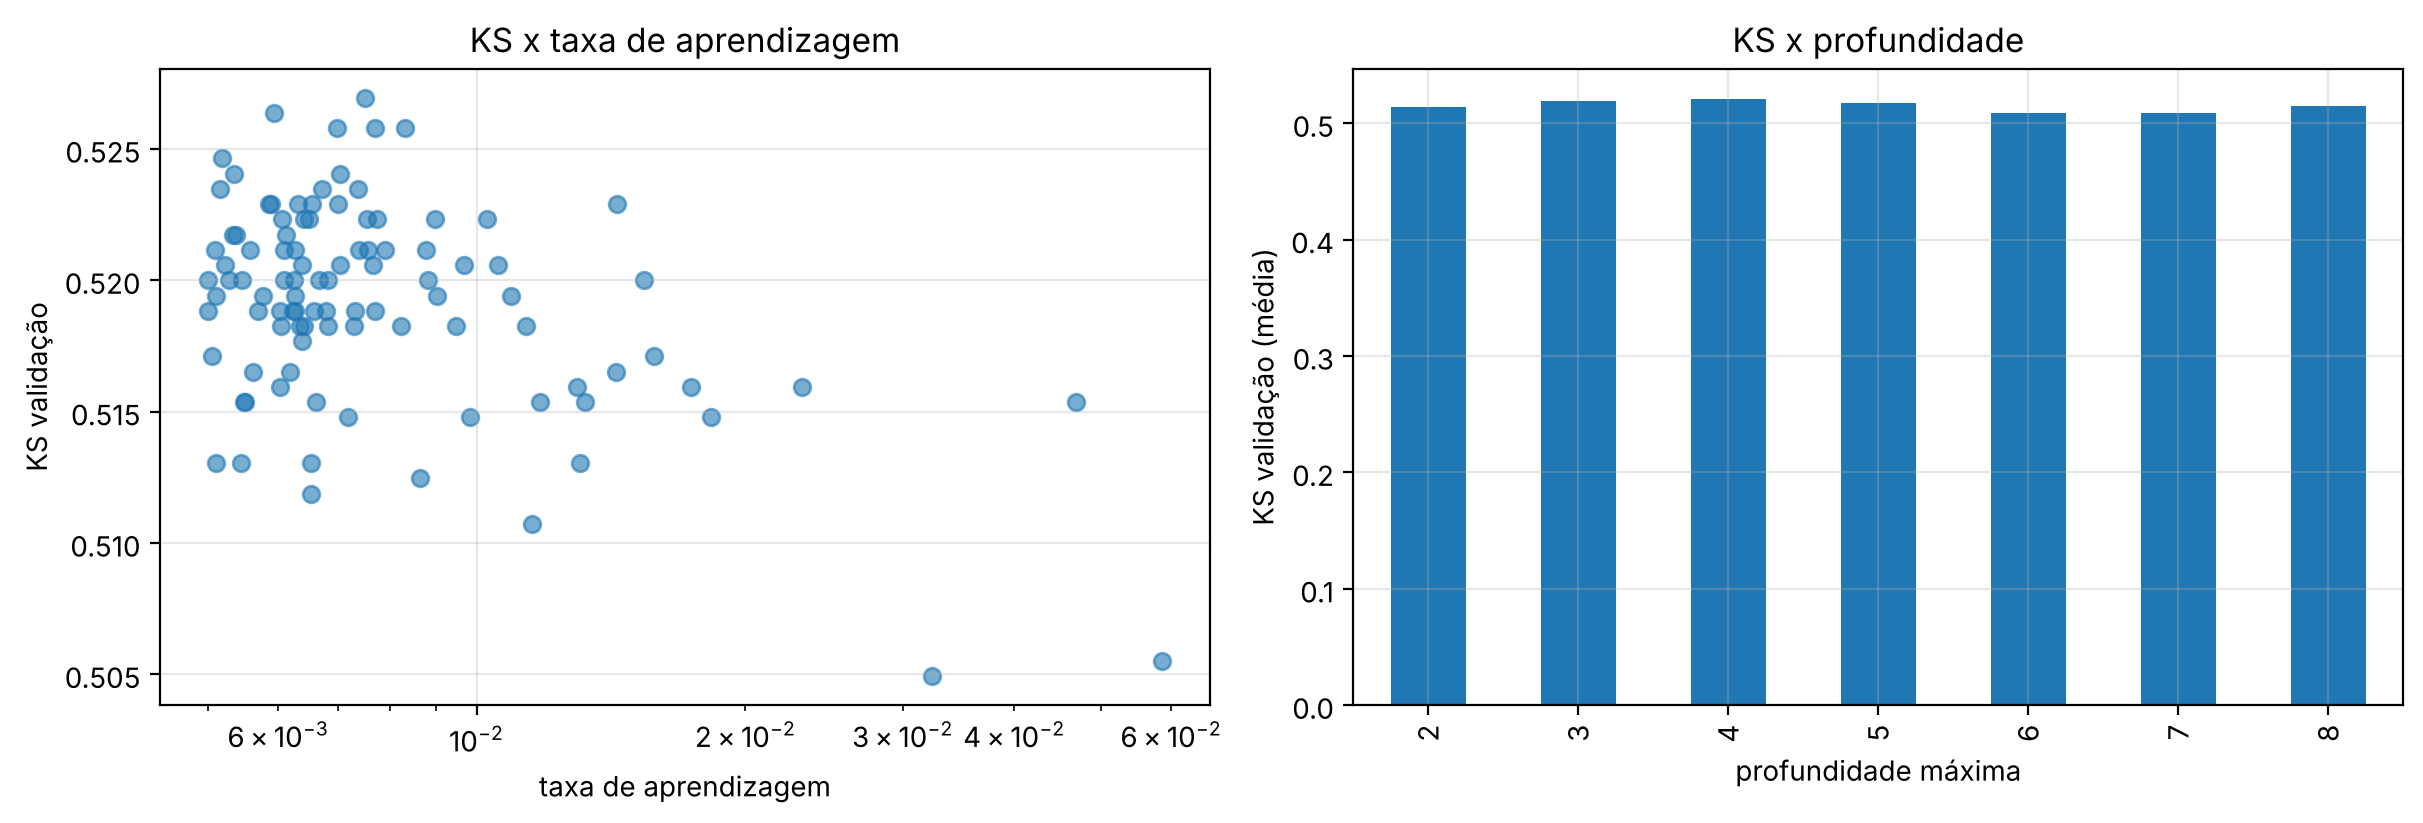

In [6]:
# Como a taxa de aprendizagem e a profundidade se relacionam com o KS de validação
t1 = xgb.trials_table(out_e1["study"])
fig, axs = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
axs[0].scatter(t1["learning_rate"], t1["val_ks"], alpha=0.6)
axs[0].set(xscale="log", xlabel="taxa de aprendizagem", ylabel="KS validação", title="KS x taxa de aprendizagem")
t1.groupby("max_depth")["val_ks"].mean().plot.bar(ax=axs[1], color="tab:blue")
axs[1].set(xlabel="profundidade máxima", ylabel="KS validação (média)", title="KS x profundidade")
for a in axs: a.grid(alpha=0.3)
save_figure(fig, "xgboost_busca_arvore_fold1")
plt.show()

## E2 — Busca de hiperparâmetros com one-hot (`neural`)
Mesmo procedimento, mas com as categóricas em one-hot. Isola o efeito da **codificação** sobre o modelo de árvores.

In [7]:
out_e2 = xgb.etapa_busca("neural", "E2_busca_onehot", n_trials=N_TRIALS, fold=FOLD_BUSCA, k=TOP_K,
                         seeds_rerank=SEEDS, seeds_registro=SEEDS, device=DEVICE, timeout=TIMEOUT_BUSCA)
print("Tentativas concluídas:", len(xgb.trials_table(out_e2["study"])))
display(out_e2["ranking"].round(4))
print("Configuração escolhida:", xgb.config_to_dict(out_e2["config"]))

  0%|          | 0/100 [00:00<?, ?it/s]

Best trial: 0. Best value: 0.524058:   0%|          | 0/100 [00:00<?, ?it/s]

Best trial: 0. Best value: 0.524058:   1%|          | 1/100 [00:00<00:34,  2.86it/s]

Best trial: 0. Best value: 0.524058:   1%|          | 1/100 [00:00<00:34,  2.86it/s]

Best trial: 0. Best value: 0.524058:   2%|▏         | 2/100 [00:00<00:23,  4.25it/s]

Best trial: 0. Best value: 0.524058:   2%|▏         | 2/100 [00:00<00:23,  4.25it/s]

... (195 outputs left out)

Best trial: 99. Best value: 0.531014: 100%|██████████| 100/100 [00:43<00:00,  2.28it/s]

Tentativas concluídas: 100


,trial,ks_trial_original,val_ks_media,val_ks_dp,val_auroc_media,sementes
0,99,0.5310,0.5246,0.0059,0.8355,3
1,27,0.5304,0.5229,0.0066,0.8355,3
2,31,0.5281,0.5215,0.0061,0.8360,3
3,62,0.5275,0.5215,0.0056,0.8358,3
4,90,0.5275,0.5210,0.0061,0.8354,3


Configuração escolhida: {'learning_rate': 0.009716627644717592, 'max_depth': 6, 'min_child_weight': 16.56689830535322, 'subsample': 0.7907630622830497, 'colsample_bytree': 0.4104827334914245, 'gamma': 0.0065603177762930225, 'reg_lambda': 0.0099988955524774, 'reg_alpha': 3.163718621113874, 'max_arvores': 2000, 'paciencia': 20}


## E3 — Resultado final nos 3 folds
Escolhemos entre E1 e E2 **pelo KS médio de validação no Fold 1** e retreinamos a vencedora nos Folds 1, 2 e 3 com 3 sementes cada.

In [8]:
resultados = load_results()
etapa_vencedora, variante_final, comparacao = xgb.melhor_etapa(resultados, ["E1_busca_arvore", "E2_busca_onehot"],
                                                               fold=FOLD_BUSCA)
print("Comparação (KS e AUROC de VALIDAÇÃO, Fold 1, média das sementes):")
display(comparacao.round(4))
print(f"Vencedora: {etapa_vencedora} (variante {variante_final})")

config_final = xgb.load_config(cfg.REPORTS_TABLES / f"xgboost_melhor_{variante_final}.json")
res_e3, saidas_e3 = xgb.etapa_final(config_final, variante_final, etapa="E3_final_3folds",
                                    folds=(1, 2, 3), seeds=SEEDS, device=DEVICE)
print("Configuração final:", xgb.config_to_dict(config_final))

Comparação (KS e AUROC de VALIDAÇÃO, Fold 1, média das sementes):


,etapa,variante,ks,auroc
0,E2_busca_onehot,neural,0.5246,0.8355
1,E1_busca_arvore,arvore,0.5229,0.8360


Vencedora: E2_busca_onehot (variante neural)


Configuração final: {'learning_rate': 0.009716627644717592, 'max_depth': 6, 'min_child_weight': 16.56689830535322, 'subsample': 0.7907630622830497, 'colsample_bytree': 0.4104827334914245, 'gamma': 0.0065603177762930225, 'reg_lambda': 0.0099988955524774, 'reg_alpha': 3.163718621113874, 'max_arvores': 2000, 'paciencia': 20}


In [9]:
resultados = load_results()
res_xgb = resultados[resultados["modelo"] == "xgboost"]
for conj in ("validacao", "teste"):
    print(f"\n=== E3 — {conj} (média ± desvio entre folds) ===")
    display(summarize_folds(res_xgb[res_xgb["etapa"] == "E3_final_3folds"], conj).round(4))

por_fold = (res_xgb[(res_xgb["etapa"] == "E3_final_3folds") & (res_xgb["conjunto"] == "teste")]
            .groupby("fold")[["ks", "auroc", "f1", "recall", "precisao", "mse", "log_loss"]].mean())
print("\nTeste por fold (média das sementes):")
display(por_fold.round(4))


=== E3 — validacao (média ± desvio entre folds) ===


,modelo,etapa,variante,ks_media,ks_dp,auroc_media,auroc_dp,f1_media,f1_dp,recall_media,recall_dp,precisao_media,precisao_dp,mse_media,mse_dp,ks_dp_sementes,sementes,folds,completo
0,xgboost,E3_final_3folds,neural,0.5336,0.011,0.8396,0.0055,0.7595,0.016,0.7604,0.0286,0.759,0.0033,0.1637,0.0033,0.0038,3,3,True



=== E3 — teste (média ± desvio entre folds) ===


,modelo,etapa,variante,ks_media,ks_dp,auroc_media,auroc_dp,f1_media,f1_dp,recall_media,recall_dp,precisao_media,precisao_dp,mse_media,mse_dp,ks_dp_sementes,sementes,folds,completo
0,xgboost,E3_final_3folds,neural,0.5369,0.0078,0.8446,0.0068,0.6286,0.0044,0.7694,0.0331,0.532,0.0106,0.1593,0.0026,0.0015,3,3,True



Teste por fold (média das sementes):


,ks,auroc,f1,recall,precisao,mse,log_loss
fold,,,,,,,
1,0.5285,0.8395,0.6235,0.7346,0.5416,0.1564,0.4741
2,0.5439,0.8523,0.6310,0.8004,0.5207,0.1604,0.4829
3,0.5383,0.8421,0.6314,0.7731,0.5336,0.1612,0.4860


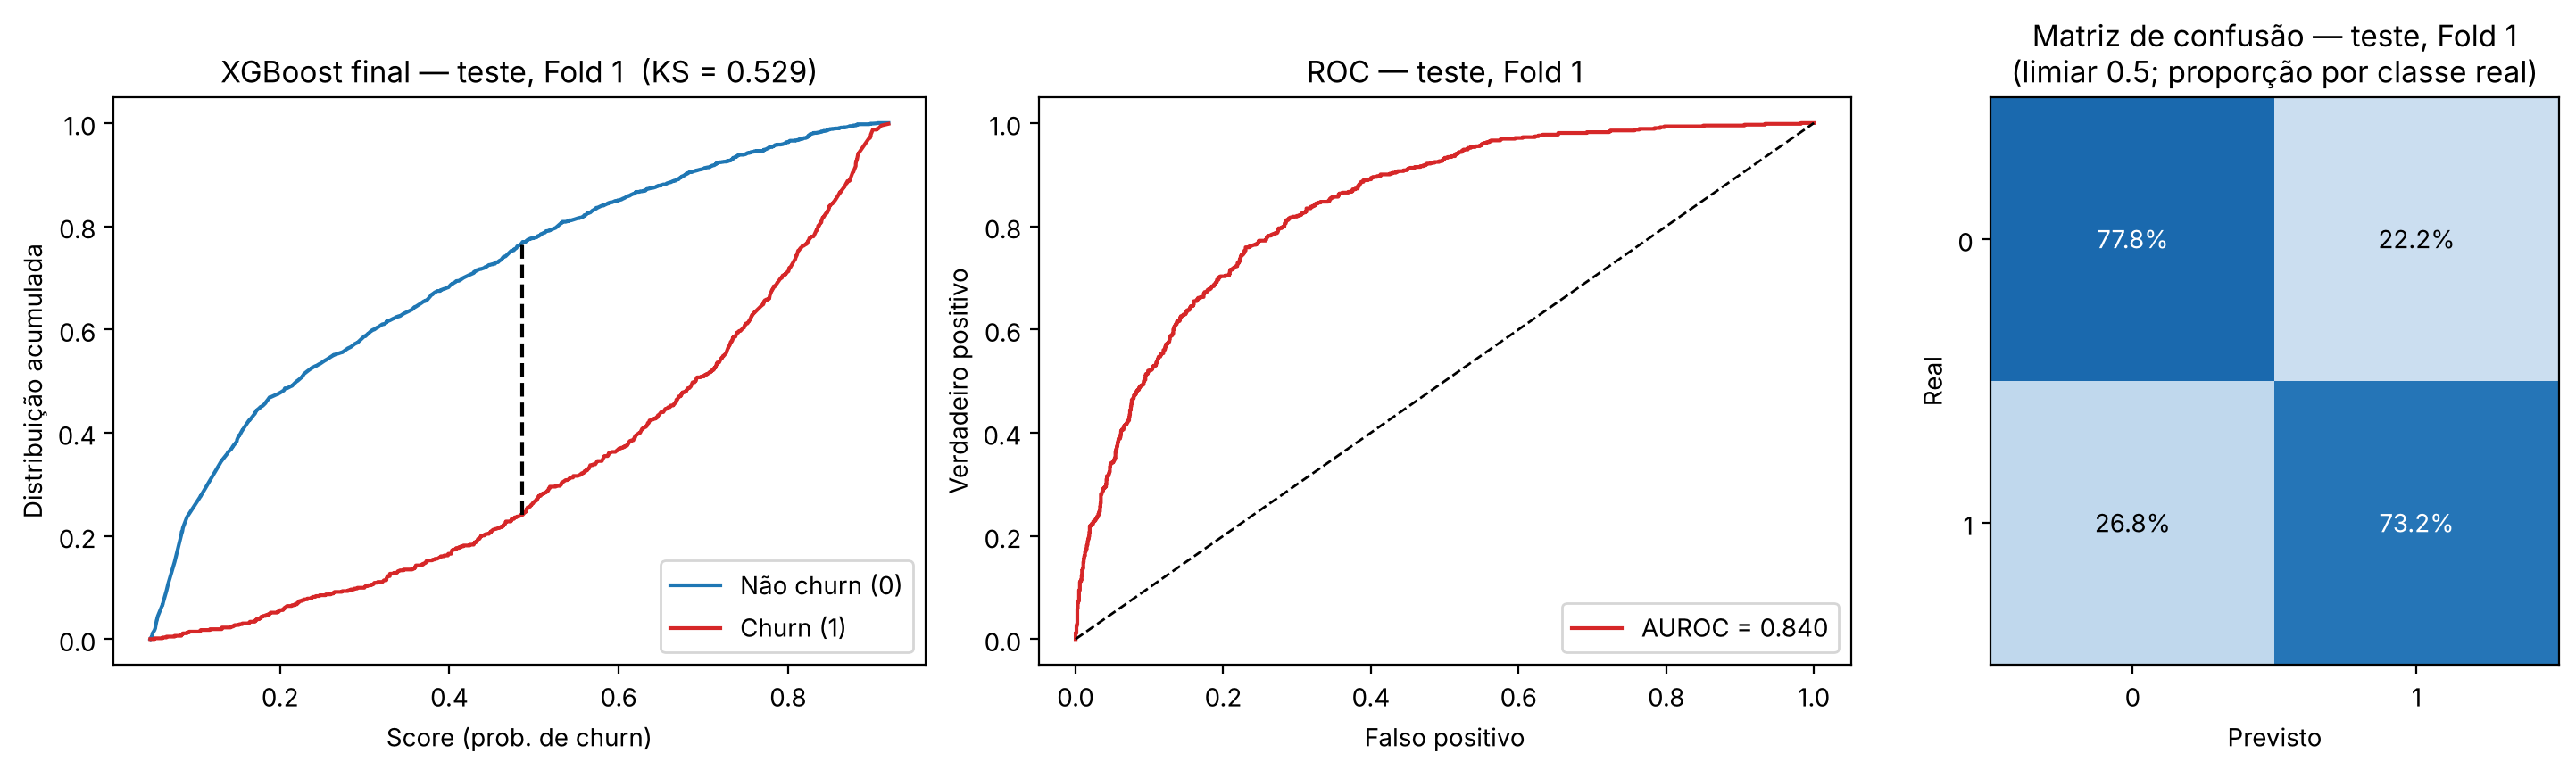

In [10]:
# Gráficos do teste (Fold 1, 1ª semente): KS, ROC e matriz de confusão
y_te, p_te = saidas_e3[1][SEEDS[0]]["scores"]["teste"]
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2), layout="constrained")
plot_ks(y_te, p_te, "XGBoost final — teste, Fold 1", ax=axs[0])
plot_roc(y_te, p_te, "ROC — teste, Fold 1", ax=axs[1])
plot_confusion(y_te, p_te, title="Matriz de confusão — teste, Fold 1", ax=axs[2])
save_figure(fig, "xgboost_final_teste_fold1")
plt.show()

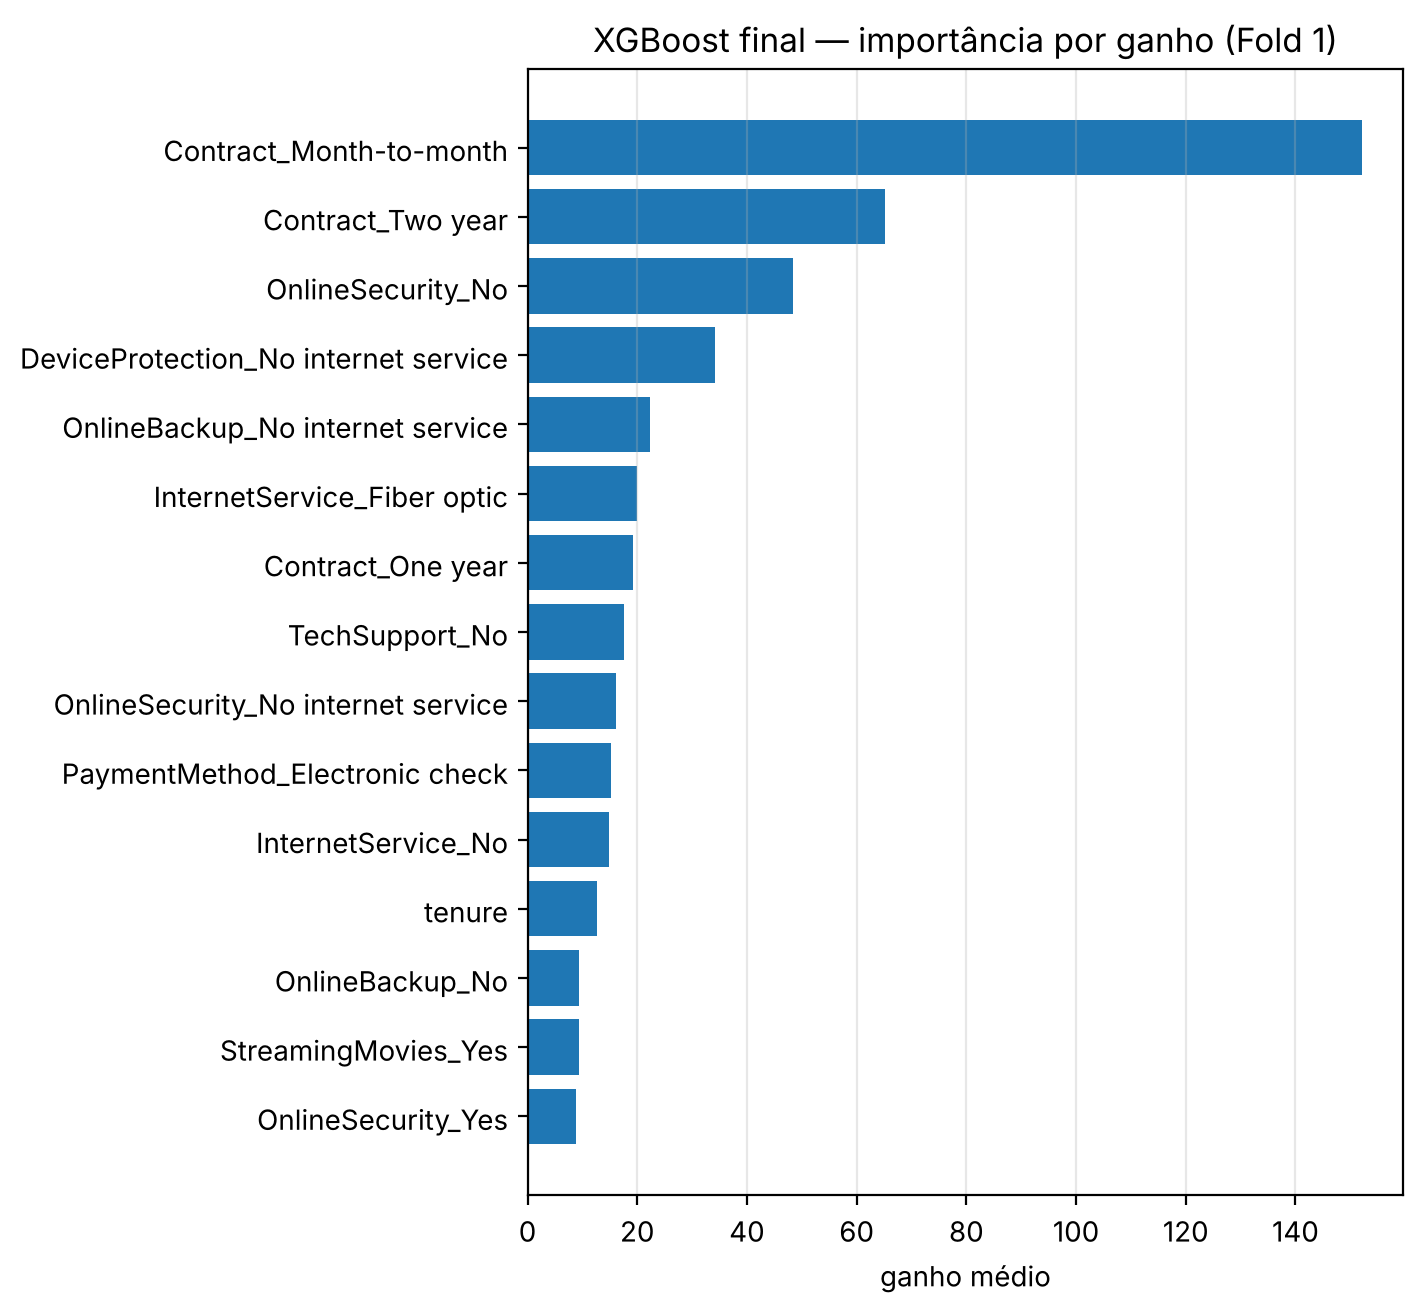

In [11]:
# Quais variáveis o modelo mais usa (ganho médio), no Fold 1
fig = xgb.plot_importancia(saidas_e3[1][SEEDS[0]]["fit"].model, top=15,
                           titulo="XGBoost final — importância por ganho (Fold 1)")
save_figure(fig, "xgboost_importancia_fold1")
plt.show()

## Evolução do desempenho
KS por etapa no **Fold 1** (barras = desvio entre sementes). A escolha usou só a validação; o teste aparece apenas como registro.

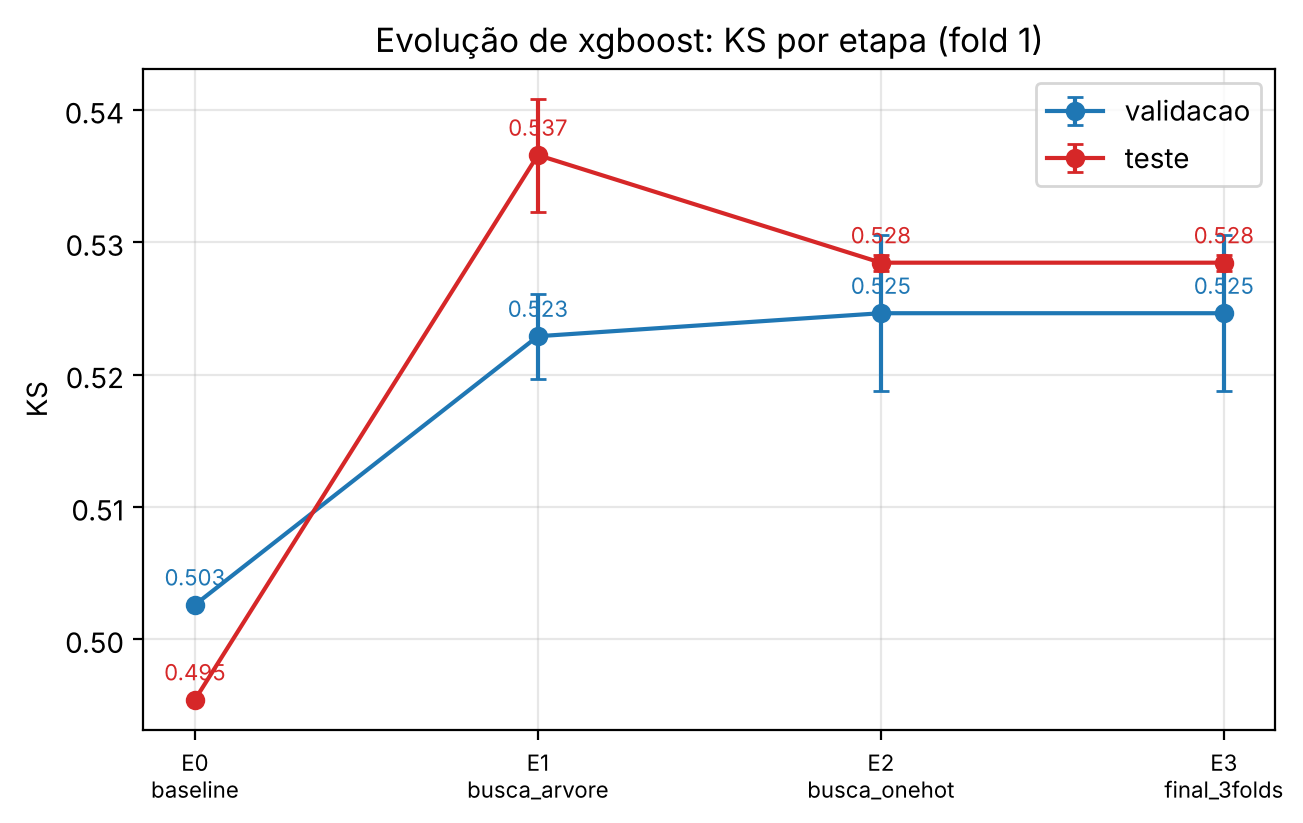

,etapa,variante,conjunto,ks,auroc,mse,log_loss,f1,folds
0,E0_baseline,arvore,treino,0.7443,0.9332,0.1153,0.3870,0.8787,1
1,E0_baseline,arvore,validacao,0.5026,0.8240,0.1732,0.5227,0.7385,1
2,E0_baseline,arvore,teste,0.4954,0.8252,0.1609,0.4875,0.6016,1
3,E1_busca_arvore,arvore,treino,0.6460,0.9003,0.1318,0.4174,0.8274,1
4,E1_busca_arvore,arvore,validacao,0.5229,0.8360,0.1655,0.5008,0.7536,1
5,E1_busca_arvore,arvore,teste,0.5366,0.8393,0.1564,0.4726,0.6287,1
6,E2_busca_onehot,neural,treino,0.6412,0.8976,0.1336,0.4239,0.8234,1
7,E2_busca_onehot,neural,validacao,0.5246,0.8355,0.1659,0.5012,0.7417,1
8,E2_busca_onehot,neural,teste,0.5285,0.8395,0.1564,0.4741,0.6235,1
9,E3_final_3folds,neural,treino,0.6412,0.8976,0.1336,0.4239,0.8234,1


In [12]:
resultados = load_results()
fig = plot_evolution(resultados, "xgboost", metric="ks", fold=FOLD_BUSCA)
save_figure(fig, "xgboost_evolucao_ks_fold1")
plt.show()
tabela_evolucao = evolution_table(resultados, "xgboost", fold=FOLD_BUSCA, metrics=("ks", "auroc", "mse", "log_loss", "f1"))
tabela_evolucao.to_csv(cfg.REPORTS_TABLES / "xgboost_evolucao_fold1.csv", index=False)
tabela_evolucao.round(4)

## XGBoost x MLP (resultado final, teste, 3 folds)

In [13]:
finais = resultados[((resultados["modelo"] == "mlp") & (resultados["etapa"] == "E4_final_3folds"))
                    | ((resultados["modelo"] == "xgboost") & (resultados["etapa"] == "E3_final_3folds"))]
summarize_folds(finais, "teste")[["modelo", "ks_media", "ks_dp", "auroc_media", "auroc_dp", "f1_media",
                                  "recall_media", "precisao_media", "folds", "sementes"]].round(4)

,modelo,ks_media,ks_dp,auroc_media,auroc_dp,f1_media,recall_media,precisao_media,folds,sementes
0,mlp,0.5400,0.0141,0.8425,0.0082,0.6228,0.7919,0.5137,3,3
1,xgboost,0.5369,0.0078,0.8446,0.0068,0.6286,0.7694,0.5320,3,3


## Registro do processo

| Etapa | O que mudou | KS validação | KS teste | Observação |
|---|---|---|---|---|
| E0_baseline | XGBoost padrão (taxa 0,3, profundidade 6), todas as variáveis, categóricas nativas (`arvore`) | 0,503 | 0,495 | Parou com só 5 árvores. KS de treino 0,744: sobreajusta muito rápido com taxa alta. |
| E1_busca_arvore | Optuna (100 tentativas) em `arvore`; escolhida: taxa 0,007, profundidade 4, subsample 0,70, colsample 0,46, ~440 árvores | 0,523 | 0,537 | Ganho grande sobre o E0 (+0,02 na validação, +0,04 no teste). Taxa baixa + árvores rasas + amostragem venceram. |
| E2_busca_onehot | Optuna (100 tentativas) em `neural` (one-hot); escolhida: taxa 0,010, profundidade 6, peso mínimo 16,6, ~330 árvores | 0,525 | 0,529 | Venceu o E1 na validação por 0,002, dentro do ruído entre sementes (0,003 a 0,006). |
| E3_final_3folds | E2 retreinada em 3 folds × 3 sementes | 0,534 ± 0,011 | 0,537 ± 0,008 | Média ± desvio entre folds. AUROC de teste 0,845 ± 0,007. Desvio entre sementes ~0,002. |

**Conclusões**
- **Ajuste importa muito no XGBoost:** o padrão da biblioteca (taxa 0,3) é ruim para essa base; a busca levou o KS de teste de 0,495 para ~0,537.
- **Padrão das melhores configurações:** taxa de aprendizagem baixa (0,005 a 0,010), centenas de árvores, amostragem de linhas e colunas (~0,5 a 0,8) e árvores rasas (profundidade 3 a 4 com categóricas nativas; 6 a 8 com one-hot, que precisa de mais divisões para separar as categorias).
- **Codificação:** nativa e one-hot ficaram empatadas na validação. Pela regra, a escolha foi pelo KS de validação (E2), mesmo o E1 tendo teste melhor no Fold 1: escolher olhando o teste seria vazamento.
- **Sobreajuste:** o KS de treino fica ~0,11 acima da validação, mais que no MLP (~0,05), mas controlado pela parada antecipada.
- **XGBoost x MLP:** KS de teste 0,537 ± 0,008 contra 0,540 ± 0,014; AUROC 0,845 contra 0,843. Empate técnico: a diferença está dentro do desvio entre folds. O XGBoost é mais estável entre folds.
- **Limitação:** MSE e log-loss do teste não são comparáveis aos da validação, porque o modelo treina com 50% de churn e o teste tem 26,5%. KS e AUROC não sofrem com isso.

## Notas de reprodutibilidade
- Resultados versionados: `reports/tables/resultados_xgboost.csv`, `optuna_xgboost_<variante>_fold1_trials.csv`, `xgboost_melhor_<variante>.json`, `xgboost_evolucao_fold1.csv`.
- Rodar a mesma célula de novo **substitui** as linhas com a mesma chave: não duplica.